# Convolutional Neutral Network (CNN)

In [120]:
import os
import glob
import copy
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import torch 
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import torch.nn.functional as F
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, 
                            f1_score, precision_score, average_precision_score, roc_auc_score,
                            classification_report, confusion_matrix, ConfusionMatrixDisplay)



In [121]:
def set_seed(seed):
    np.random.seed(seed)
    torch.manual_seed(seed=42)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

## <font color="orange">Load MFCCs and specify labels and groups </font>

In [122]:
# emotion
EMO = {"W":"anger","L":"boredom",
    "E":"disgust","A":"fear",
    "F":"happiness","T":"sadness","N":"neutral"}

# read all all mfcc csv files
paths = sorted(glob.glob("../data/extraction/mfcc_mat/*.csv")) 
mfccs, labels, groups = [], [], []
for p in paths:
    name = os.path.splitext(os.path.basename(p))[0]  # e.g. 03a01Fa
    m = pd.read_csv(p, header=None).values.astype(np.float32) #(n_frames, n_mfcc)
    mfccs.append(m)
    groups.append(name[:2])           # speaker id
    labels.append(EMO[name[5]])       # emotion letter

# encode the target
le = LabelEncoder()
y = le.fit_transform(labels)
groups = np.array(groups)
print(len(mfccs), le.classes_, np.unique(groups))

567 ['anger' 'boredom' 'disgust' 'fear' 'happiness' 'neutral' 'sadness'] ['03' '08' '09' '10' '11' '12' '13' '14' '15' '16']


## <font color="orange"> Preparation </font>

In [123]:
def fix_len(m, T):
    """Crop or zero-pad along frames dim to exactly T frames."""
    if m.shape[0] >= T:
        return m[:T]
    return np.pad(m, ((0, T - m.shape[0]), (0, 0)))

In [124]:
# choose the test and validation groups
test_spk = ["09", "14"] # 1 male + 1 female
val_spk  = ["10", "15"] # 1 male + 1 female

# filter machines
is_test = np.isin(groups, test_spk)
is_val  = np.isin(groups, val_spk)
is_tr   = ~(is_test | is_val)

# Set T
T = int(np.percentile([m.shape[0] for m, t in zip(mfccs, is_tr) if t], 95))
print(f"T = {T}")

# mean/std over all unpadded/uncropped train frames for each mfcc
# (only train)
#tr_frames = np.concatenate([m for m, t in zip(mfccs, is_tr) if t], axis=0)
#mean, std = tr_frames.mean(0), tr_frames.std(0) + 1e-8
# Normalize first, then crop/pad
#X = np.stack([fix_len((m - mean) / std, T) for m in mfccs]).astype(np.float32)

spk_stats = {}
for g in np.unique(groups):
    frames = np.concatenate([m for m, gg in zip(mfccs, groups) if gg == g])
    spk_stats[g] = (frames.mean(0), frames.std(0) + 1e-8)

X = np.stack([fix_len((m - spk_stats[g][0]) / spk_stats[g][1], T)
            for m, g in zip(mfccs, groups)]).astype(np.float32)

# split
split = {}
for name, mask in [("train", is_tr), ("val", is_val), ("test", is_test)]:
    split[name] = (X[mask], y[mask])

(Xtr, ytr) = split["train"] 
(Xva, yva) = split["val"]
(Xte, yte) = split["test"]

n_mfcc = Xtr.shape[2]

print("Train/test/val split ok!")

T = 503
Train/test/val split ok!


In [125]:
# compute class weights
n_classes = len(le.classes_)
counts = np.bincount(ytr, minlength=n_classes)
class_weights = counts.sum() / (n_classes * np.maximum(counts, 1))
print(le.classes_)
print(class_weights)

['anger' 'boredom' 'disgust' 'fear' 'happiness' 'neutral' 'sadness']
[0.63079777 0.88311688 2.02380952 1.21428571 1.01190476 0.97142857
 1.05590062]


In [126]:
# augmentation (use in train)
# masking + small gaussian noise
def augment(x, max_t=25, max_f=8, noise=0.05):
    """x is batch of shape (B,T,F): batch size, time frames, MFCC coeffs"""
    x = x.clone() # keep original batch safe
    B, T, F = x.shape
    for i in range(B):
        # time frame mask
        t = np.random.randint(0, max_t+1) # random mask width
        t0 = np.random.randint(0, max(T-t,1)) # random start position of the mask
        x[i, t0:t0+t, :] = 0 # masking with 0 -> nrutral info
        
        #frequency mask (on the MFCC axis)
        f = np.random.randint(0, max_f+1)
        f0 = np.random.randint(0, max(F-f,1))
        x[i, :, f0:f0+f] = 0
    # gaussian noise
    xn = x + noise * torch.rand_like(x)
    return xn

In [127]:
# loader
def make_loader(X, y, shuffle, batch=16):
    ds = TensorDataset(torch.from_numpy(X), torch.from_numpy(y).long())
    return DataLoader(ds, batch_size=batch, shuffle=shuffle)

## <font color="orange"> CNN Construction </font>

### **1D CNN**

In [128]:
# 1D convolutional block
def conv_block_1d(cin, cout):
    return nn.Sequential(
        # filters along time axis, each filter looks at 5 consecutive frames 
        #-> padding=2
        nn.Conv1d(cin, cout, kernel_size=5, padding=2),
        nn.BatchNorm1d(cout),
        nn.ReLU(),
        nn.MaxPool1d(2),
    )

In [129]:
# convolves over time 
# MFCC are channels
class MFCCNet1D(nn.Module):
    def __init__(self, n_mfcc, n_classes, dropout=0.5):
        super().__init__()
        # learns pattern over time
        nc1, nc2, nc3, nc4 = 64, 128, 128, 64
        self.features = nn.Sequential(
            conv_block_1d(n_mfcc, nc1), 
            conv_block_1d(nc1, nc2),
            conv_block_1d(nc2, nc3),
            nn.AdaptiveAvgPool1d(1) # global average and leaving 1 per channel
        )
        # fully connected layers turning pattern into emotion scores
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(nc3, nc4), # a hidden FC layer
            nn.ReLU(), # add nonlinearity
            nn.Dropout(dropout), # reduce overfitting by randomly zeroing dropout ratio of 64 values during training
            nn.Linear(nc4, n_classes), # output 1 raw score per emotion
        )
    def forward(self, x):
        return self.classifier(self.features(x.transpose(1,2)))


### **2D CNN**

In [130]:
def conv_block_2d(cin, cout):
    return nn.Sequential(
        nn.Conv2d(cin, cout, kernel_size=3, padding=1),
        nn.BatchNorm2d(cout),
        nn.ReLU(),
        nn.MaxPool2d(2)
    )

In [131]:
# CNN 2D: treat (T, n_mfcc) as a 1-channel image
class MFCCNet2D(nn.Module):
    def __init__(self, n_classes, dropout=0.5):
        super().__init__()
        # features extraction
        self.features = nn.Sequential(
            conv_block_2d(1,64),
            conv_block_2d(64,128),
            conv_block_2d(128,128),
            nn.AdaptiveAvgPool2d(1),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128, 64),
            nn.Dropout(dropout),
            nn.Linear(64, n_classes),
        )

    def forward(self, x):  # x: (B, T, n_mfcc)
        return self.classifier(self.features(x.unsqueeze(1))) 

## <font color="orange"> Training </font>

In [132]:
@torch.no_grad()
def predict(model, loader, device="cpu"):
    model.eval()
    preds, ys = [], []
    for x, y in loader:
        preds.append(model(x.to(device)).argmax(1).cpu().numpy())
        ys.append(y.numpy())
    return np.concatenate(ys), np.concatenate(preds)

In [ ]:
def train(model, train_loader, val_loader, 
        epochs=30, lr=1e-3, device="cpu", weight_decay=6e-4,
        class_weights=class_weights):
    model.to(device) # cpu or cuda
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    #decay, no_decay = [], []
    #for n, p in model.named_parameters():
    #    if not p.requires_grad:
    #        continue
    #    (no_decay if p.ndim <= 1 else decay).append(p)   # biases + BN params get no decay

    #opt = torch.optim.AdamW(
    #    [{"params": decay, "weight_decay": 1e-2},
    #    {"params": no_decay, "weight_decay": 0.0}],
    #    lr=5e-4,
    #)

    #warmup = torch.optim.lr_scheduler.LinearLR(opt, start_factor=0.1, total_iters=3)
    #cosine = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs - 3, eta_min=1e-5)
    #sched = torch.optim.lr_scheduler.SequentialLR(opt, [warmup, cosine], milestones=[3])
    loss_fn = nn.CrossEntropyLoss(
        weight=torch.tensor(class_weights, dtype=torch.float32, device=device),
        label_smoothing=0.1
    )
    best_uar, best_state, bad = -1.0, None, 0
    train_uar, val_uar, eps = [], [], []
    for epoch in range(epochs):
        model.train()
        tot = 0.0
        for x, y in train_loader:
            x, y = augment(x).to(device), y.to(device)
            opt.zero_grad()
            loss = loss_fn(model(x), y)
            loss.backward()
            opt.step()
            tot += loss.item() * len(y)
        sched.step()
        yv, pv = predict(model, val_loader, device=device)
        yt, pt = predict(model, make_loader(Xtr, ytr, False))
        tr_uar = balanced_accuracy_score(yt, pt) # unweighted (macro) average recall
        uar = balanced_accuracy_score(yv, pv)  
        print(f"train UAR {tr_uar:.3f} | val UAR {uar:.3f}")
        train_uar.append(tr_uar)
        val_uar.append(uar)
        eps.append(epoch+1)
        if (epoch+1) % 2 == 0 or epoch == 0:
            print(f"epoch {epoch+1:3d} | loss {tot / len(train_loader.dataset):.3f} "
                f"| val acc {accuracy_score(yv, pv):.3f} | val UAR {uar:.3f}")
        if uar > best_uar:
            best_uar, best_state, bad = uar, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= 20:
                print(f"early stop at epoch {epoch} (best val UAR {best_uar:.3f})")
                break
    model.load_state_dict(best_state)
    return model, train_uar, val_uar, eps

### 1D CNN

In [134]:
# run
def run_1D_CNN(seed):
    set_seed(seed)
    cnn_model_1D = MFCCNet1D(n_mfcc, n_classes)
    epochs = 40
    model_1D, train_uar, val_uar, eps = train(
            cnn_model_1D, 
            make_loader(Xtr, ytr, True),
            make_loader(Xva, yva, False),
            epochs=epochs, lr=5e-4, weight_decay=1e-4
        )
    yt, pt = predict(model_1D, make_loader(Xte, yte, False))
    print(f"\nTEST accuracy {accuracy_score(yt, pt):.3f} | "
    f"UAR {balanced_accuracy_score(yt, pt):.3f}")
    return model_1D, train_uar, val_uar, eps, yt, pt

train UAR 0.327 | val UAR 0.272
epoch   1 | loss 1.918 | val acc 0.212 | val UAR 0.272
train UAR 0.496 | val UAR 0.365
epoch   2 | loss 1.789 | val acc 0.346 | val UAR 0.365
train UAR 0.589 | val UAR 0.479
train UAR 0.603 | val UAR 0.461
epoch   4 | loss 1.642 | val acc 0.519 | val UAR 0.461
train UAR 0.668 | val UAR 0.542
train UAR 0.715 | val UAR 0.658
epoch   6 | loss 1.504 | val acc 0.692 | val UAR 0.658
train UAR 0.710 | val UAR 0.616
train UAR 0.819 | val UAR 0.714
epoch   8 | loss 1.419 | val acc 0.712 | val UAR 0.714
train UAR 0.800 | val UAR 0.716
train UAR 0.801 | val UAR 0.715
epoch  10 | loss 1.369 | val acc 0.721 | val UAR 0.715
train UAR 0.800 | val UAR 0.682
train UAR 0.783 | val UAR 0.697
epoch  12 | loss 1.325 | val acc 0.692 | val UAR 0.697
train UAR 0.825 | val UAR 0.753
train UAR 0.820 | val UAR 0.683
epoch  14 | loss 1.256 | val acc 0.692 | val UAR 0.683
train UAR 0.831 | val UAR 0.747
train UAR 0.889 | val UAR 0.753
epoch  16 | loss 1.227 | val acc 0.750 | val UAR

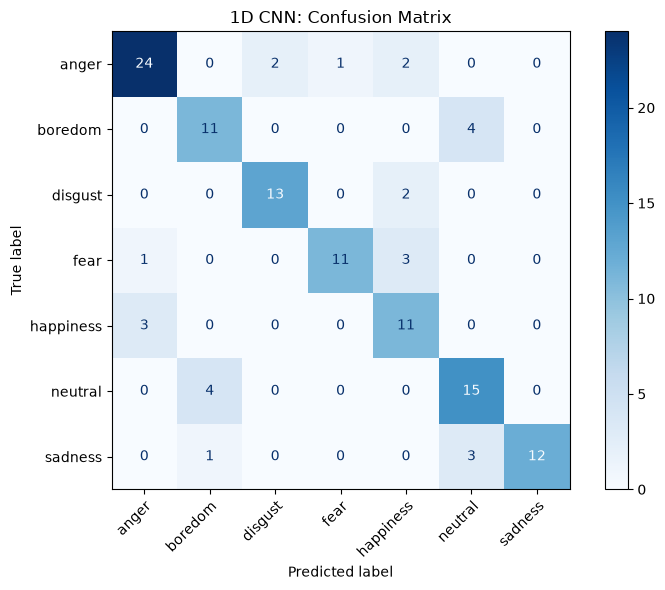

              precision    recall  f1-score   support

       anger       0.86      0.83      0.84        29
     boredom       0.69      0.73      0.71        15
     disgust       0.87      0.87      0.87        15
        fear       0.92      0.73      0.81        15
   happiness       0.61      0.79      0.69        14
     neutral       0.68      0.79      0.73        19
     sadness       1.00      0.75      0.86        16

    accuracy                           0.79       123
   macro avg       0.80      0.78      0.79       123
weighted avg       0.81      0.79      0.79       123



In [135]:
model_1D, train_uar, val_uar, eps, yt, pt = run_1D_CNN(seed=42)

labels = np.arange(n_classes)
cm = confusion_matrix(yt, pt, labels=labels)
fig, ax = plt.subplots(figsize=(8, 6))
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=le.classes_,
)
display.plot(ax=ax, cmap="Blues", values_format="d")
ax.set_title("1D CNN: Confusion Matrix")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
plt.tight_layout()
plt.show()

print(classification_report(
    yt,
    pt,
    labels=labels,
    target_names=le.classes_,
    zero_division=0
))



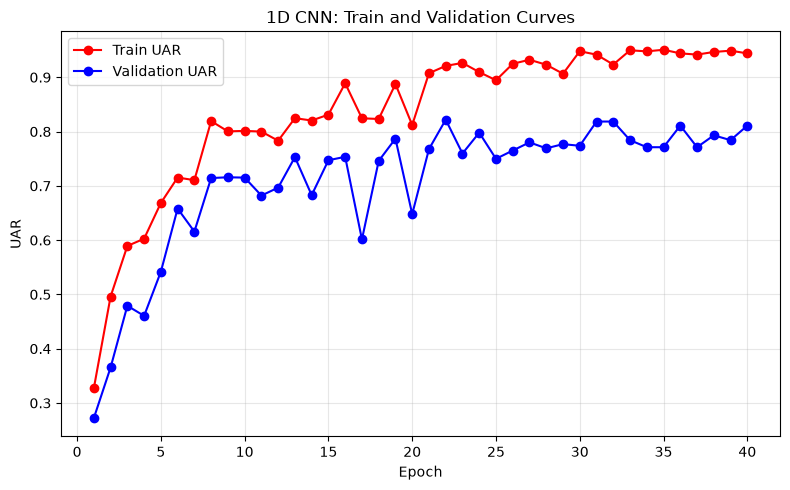

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(eps, train_uar, color="red", marker="o", markevery=1, label="Train UAR")
plt.plot(eps, val_uar, color="blue", marker="o", markevery=1, label="Validation UAR")
plt.xlabel("Epoch")
plt.ylabel("UAR")
plt.title("1D CNN: Train and Validation Curves (seed=42)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [137]:

# run 5 seeds
results = []

for seed in range(1, 6):
    model, _, _, _, y_true, _ = run_1D_CNN(seed=seed)

    model.eval()
    test_loader = make_loader(Xte, yte, shuffle=False)
    probabilities = []

    with torch.no_grad():
        for x, _ in test_loader:
            probabilities.append(torch.softmax(model(x), dim=1).cpu().numpy())

    probabilities = np.concatenate(probabilities)
    y_onehot = np.eye(n_classes)[y_true]

    results.append({
        "seed": seed,
        "macro_precision": precision_score(
            y_true, probabilities.argmax(axis=1),
            labels=np.arange(n_classes), average="macro", zero_division=0
        ),
        "balanced_accuracy": balanced_accuracy_score(
            y_true, probabilities.argmax(axis=1)
        ),
        "macro_f1": f1_score(
            y_true, probabilities.argmax(axis=1),
            labels=np.arange(n_classes), average="macro", zero_division=0
        ),
        "PR-AUC": average_precision_score(
            y_onehot, probabilities, average="macro"
        ),
        "ROC-AUC": roc_auc_score(
            y_onehot, probabilities, average="macro"
        ),
    })

results_df = pd.DataFrame(results).set_index("seed")
summary = pd.DataFrame({
    "mean": results_df.mean(),
    "stdev": results_df.std(ddof=1),
})

print(results_df)
print(summary)

train UAR 0.372 | val UAR 0.267
epoch   1 | loss 1.911 | val acc 0.231 | val UAR 0.267
train UAR 0.489 | val UAR 0.368
epoch   2 | loss 1.781 | val acc 0.308 | val UAR 0.368
train UAR 0.602 | val UAR 0.520
train UAR 0.614 | val UAR 0.556
epoch   4 | loss 1.634 | val acc 0.577 | val UAR 0.556
train UAR 0.610 | val UAR 0.531
train UAR 0.682 | val UAR 0.654
epoch   6 | loss 1.488 | val acc 0.663 | val UAR 0.654
train UAR 0.679 | val UAR 0.653
train UAR 0.736 | val UAR 0.646
epoch   8 | loss 1.420 | val acc 0.663 | val UAR 0.646
train UAR 0.700 | val UAR 0.707
train UAR 0.743 | val UAR 0.695
epoch  10 | loss 1.369 | val acc 0.712 | val UAR 0.695
train UAR 0.719 | val UAR 0.659
train UAR 0.739 | val UAR 0.673
epoch  12 | loss 1.322 | val acc 0.673 | val UAR 0.673
train UAR 0.855 | val UAR 0.654
train UAR 0.811 | val UAR 0.718
epoch  14 | loss 1.270 | val acc 0.721 | val UAR 0.718
train UAR 0.786 | val UAR 0.659
train UAR 0.837 | val UAR 0.734
epoch  16 | loss 1.252 | val acc 0.740 | val UAR

### 2D CNN


train UAR 0.401 | val UAR 0.388
epoch   1 | loss 1.945 | val acc 0.356 | val UAR 0.388
train UAR 0.480 | val UAR 0.474
epoch   2 | loss 1.728 | val acc 0.500 | val UAR 0.474
train UAR 0.454 | val UAR 0.427
train UAR 0.224 | val UAR 0.184
epoch   4 | loss 1.624 | val acc 0.269 | val UAR 0.184
train UAR 0.288 | val UAR 0.277
train UAR 0.500 | val UAR 0.397
epoch   6 | loss 1.618 | val acc 0.442 | val UAR 0.397
train UAR 0.506 | val UAR 0.453
train UAR 0.500 | val UAR 0.468
epoch   8 | loss 1.537 | val acc 0.510 | val UAR 0.468
train UAR 0.366 | val UAR 0.275
train UAR 0.452 | val UAR 0.366
epoch  10 | loss 1.521 | val acc 0.375 | val UAR 0.366
train UAR 0.575 | val UAR 0.476
train UAR 0.579 | val UAR 0.450
epoch  12 | loss 1.473 | val acc 0.490 | val UAR 0.450
train UAR 0.650 | val UAR 0.600
train UAR 0.556 | val UAR 0.508
epoch  14 | loss 1.448 | val acc 0.577 | val UAR 0.508
train UAR 0.645 | val UAR 0.585
train UAR 0.374 | val UAR 0.354
epoch  16 | loss 1.389 | val acc 0.308 | val UAR

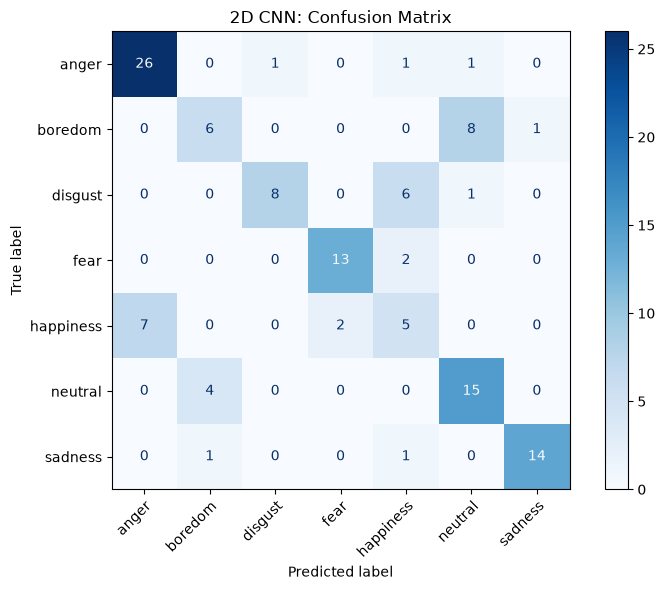

              precision    recall  f1-score   support

       anger       0.86      0.83      0.84        29
     boredom       0.69      0.73      0.71        15
     disgust       0.87      0.87      0.87        15
        fear       0.92      0.73      0.81        15
   happiness       0.61      0.79      0.69        14
     neutral       0.68      0.79      0.73        19
     sadness       1.00      0.75      0.86        16

    accuracy                           0.79       123
   macro avg       0.80      0.78      0.79       123
weighted avg       0.81      0.79      0.79       123



In [138]:
# 2D CNN
def run_2D_CNN(seed):
    set_seed(seed)

    cnn_model_2D = MFCCNet2D(n_classes)
    model_2D, train_uar, val_uar, eps = train(
        cnn_model_2D,
        make_loader(Xtr, ytr, shuffle=True),
        make_loader(Xva, yva, shuffle=False),
        epochs=40,
        lr=5e-3,
        weight_decay=1e-3,
    )

    y_true, y_pred = predict(
        model_2D,
        make_loader(Xte, yte, shuffle=False),
    )
    print(
        f"\nSeed {seed} - TEST accuracy "
        f"{accuracy_score(y_true, y_pred):.3f} | "
        f"UAR {balanced_accuracy_score(y_true, y_pred):.3f}"
    )

    return model_2D, train_uar, val_uar, eps, y_true, y_pred

# run for one seed
model_2D, train_uar_2d, val_uar_2d, eps_2d, y_true, y_pred = run_2D_CNN(42)
labels = np.arange(n_classes)
cm = confusion_matrix(y_true, y_pred, labels=labels)
fig, ax = plt.subplots(figsize=(8, 6))
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=le.classes_,
)
display.plot(ax=ax, cmap="Blues", values_format="d")
ax.set_title("2D CNN: Confusion Matrix")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
plt.tight_layout()
plt.show()

print(classification_report(
    yt,
    pt,
    labels=labels,
    target_names=le.classes_,
    zero_division=0
))


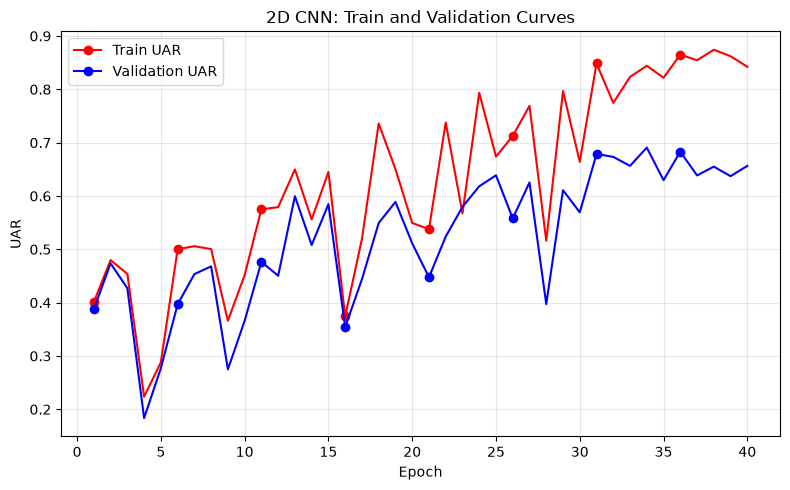

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(eps_2d, train_uar_2d, color="red", marker="o", markevery=1, label="Train UAR")
plt.plot(eps_2d, val_uar_2d, color="blue", marker="o", markevery=1, label="Validation UAR")
plt.xlabel("Epoch")
plt.ylabel("UAR")
plt.title("2D CNN: Train and Validation Curves")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
results_2d = []

for seed in range(1, 6):
    model, _, _, _, y_true, _ = run_2D_CNN(seed=seed)

    model.eval()
    probabilities = []

    with torch.no_grad():
        for x, _ in make_loader(Xte, yte, shuffle=False):
            probabilities.append(
                torch.softmax(model(x), dim=1).cpu().numpy()
            )

    probabilities = np.concatenate(probabilities)
    y_pred = probabilities.argmax(axis=1)
    y_onehot = np.eye(n_classes)[y_true]

    results_2d.append({
        "seed": seed,
        "macro_precision": precision_score(
            y_true, y_pred,
            labels=np.arange(n_classes),
            average="macro",
            zero_division=0,
        ),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(
            y_true, y_pred,
            labels=np.arange(n_classes),
            average="macro",
            zero_division=0,
        ),
        "PR-AUC": average_precision_score(
            y_onehot, probabilities, average="macro"
        ),
        "ROC-AUC": roc_auc_score(
            y_onehot, probabilities, average="macro"
        ),
    })

results_df_2d = pd.DataFrame(results_2d).set_index("seed")
summary_2d = pd.DataFrame({
    "mean": results_df_2d.mean(),
    "stdev": results_df_2d.std(ddof=1),
})

print(results_df_2d)
print(summary_2d)

train UAR 0.303 | val UAR 0.264
epoch   1 | loss 1.938 | val acc 0.308 | val UAR 0.264
train UAR 0.385 | val UAR 0.385
epoch   2 | loss 1.766 | val acc 0.442 | val UAR 0.385
train UAR 0.467 | val UAR 0.459
train UAR 0.379 | val UAR 0.298
epoch   4 | loss 1.611 | val acc 0.365 | val UAR 0.298
train UAR 0.306 | val UAR 0.355
train UAR 0.481 | val UAR 0.391
epoch   6 | loss 1.615 | val acc 0.462 | val UAR 0.391
train UAR 0.438 | val UAR 0.439
train UAR 0.533 | val UAR 0.489
epoch   8 | loss 1.542 | val acc 0.510 | val UAR 0.489
train UAR 0.433 | val UAR 0.288
train UAR 0.534 | val UAR 0.410
epoch  10 | loss 1.523 | val acc 0.442 | val UAR 0.410
train UAR 0.594 | val UAR 0.507
train UAR 0.627 | val UAR 0.527
epoch  12 | loss 1.483 | val acc 0.558 | val UAR 0.527
train UAR 0.388 | val UAR 0.395
train UAR 0.560 | val UAR 0.533
epoch  14 | loss 1.428 | val acc 0.606 | val UAR 0.533
train UAR 0.609 | val UAR 0.538
train UAR 0.513 | val UAR 0.455
epoch  16 | loss 1.362 | val acc 0.385 | val UAR